In [1]:
!pip install requests beautifulsoup4 pandas numpy matplotlib seaborn openpyxl lxml


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import openpyxl

from urllib.parse import urljoin

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
import requests

url = "https://books.toscrape.com/"

response = requests.get(url)

print("Status Code:", response.status_code)
print("Website HTML:")
print(response.text[:500])

Status Code: 200
Website HTML:
<!DOCTYPE html>
<!--[if lt IE 7]>      <html lang="en-us" class="no-js lt-ie9 lt-ie8 lt-ie7"> <![endif]-->
<!--[if IE 7]>         <html lang="en-us" class="no-js lt-ie9 lt-ie8"> <![endif]-->
<!--[if IE 8]>         <html lang="en-us" class="no-js lt-ie9"> <![endif]-->
<!--[if gt IE 8]><!--> <html lang="en-us" class="no-js"> <!--<![endif]-->
    <head>
        <title>
    All products | Books to Scrape - Sandbox
</title>

        <meta http-equiv="content-type" content="text/html; charset=UTF-8" /


In [5]:
# Convert HTML into a BeautifulSoup object
soup = BeautifulSoup(response.text, "html.parser")

# Find all product cards
products = soup.find_all("article", class_="product_pod")

print("Total products found:", len(products))

# Extract first 5 products
for product in products[:5]:

    name = product.find("h3").find("a")["title"]

    price = product.find("p", class_="price_color").text

    print("Product Name:", name)
    print("Price:", price)
    print("----------------------")

Total products found: 20
Product Name: A Light in the Attic
Price: Â£51.77
----------------------
Product Name: Tipping the Velvet
Price: Â£53.74
----------------------
Product Name: Soumission
Price: Â£50.10
----------------------
Product Name: Sharp Objects
Price: Â£47.82
----------------------
Product Name: Sapiens: A Brief History of Humankind
Price: Â£54.23
----------------------


In [6]:
# Create an empty list
product_data = []

# Extract all products
for product in products:

    name = product.find("h3").find("a")["title"]

    price = product.find("p", class_="price_color").text

    rating = product.find("p", class_="star-rating")["class"][1]

    product_data.append({
        "Product_Name": name,
        "Price": price,
        "Rating": rating
    })

# Convert list into DataFrame
df = pd.DataFrame(product_data)

# Display the dataset
print(df)

                                         Product_Name    Price Rating
0                                A Light in the Attic  Â£51.77  Three
1                                  Tipping the Velvet  Â£53.74    One
2                                          Soumission  Â£50.10    One
3                                       Sharp Objects  Â£47.82   Four
4               Sapiens: A Brief History of Humankind  Â£54.23   Five
5                                     The Requiem Red  Â£22.65    One
6   The Dirty Little Secrets of Getting Your Dream...  Â£33.34   Four
7   The Coming Woman: A Novel Based on the Life of...  Â£17.93  Three
8   The Boys in the Boat: Nine Americans and Their...  Â£22.60   Four
9                                     The Black Maria  Â£52.15    One
10     Starving Hearts (Triangular Trade Trilogy, #1)  Â£13.99    Two
11                              Shakespeare's Sonnets  Â£20.66   Four
12                                        Set Me Free  Â£17.46   Five
13  Scott Pilgrim's 

In [7]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nFirst 5 Records:")
display(df.head())

Dataset Shape: (20, 3)

Column Names:
Index(['Product_Name', 'Price', 'Rating'], dtype='str')

First 5 Records:


,Product_Name,Price,Rating
0,A Light in the Attic,Â£51.77,Three
1,Tipping the Velvet,Â£53.74,One
2,Soumission,Â£50.10,One
3,Sharp Objects,Â£47.82,Four
4,Sapiens: A Brief History of Humankind,Â£54.23,Five


In [8]:
from urllib.parse import urljoin

base_url = "https://books.toscrape.com/"
current_url = base_url

all_products = []

while current_url:

    response = requests.get(current_url)
    soup = BeautifulSoup(response.text, "html.parser")

    products = soup.find_all("article", class_="product_pod")

    for product in products:

        name = product.find("h3").find("a")["title"]
        price = product.find("p", class_="price_color").text
        rating = product.find("p", class_="star-rating")["class"][1]

        all_products.append({
            "Product_Name": name,
            "Price": price,
            "Rating": rating
        })

    next_button = soup.find("li", class_="next")

    if next_button:
        next_page = next_button.find("a")["href"]
        current_url = urljoin(current_url, next_page)
    else:
        current_url = None

print("Total products collected:", len(all_products))

Total products collected: 1000


In [9]:
df_all = pd.DataFrame(all_products)

display(df_all.head())

print("Dataset Shape:", df_all.shape)


,Product_Name,Price,Rating
0,A Light in the Attic,Â£51.77,Three
1,Tipping the Velvet,Â£53.74,One
2,Soumission,Â£50.10,One
3,Sharp Objects,Â£47.82,Four
4,Sapiens: A Brief History of Humankind,Â£54.23,Five


Dataset Shape: (1000, 3)


In [10]:
# Display all column names

print("Column Names:")
print(df_all.columns.tolist())

# Display dataset information

print("\nDataset Information:")
df_all.info()

# Display first 5 records

display(df_all.head())

Column Names:
['Product_Name', 'Price', 'Rating']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   Product_Name  1000 non-null   str  
 1   Price         1000 non-null   str  
 2   Rating        1000 non-null   str  
dtypes: str(3)
memory usage: 74.3 KB


,Product_Name,Price,Rating
0,A Light in the Attic,Â£51.77,Three
1,Tipping the Velvet,Â£53.74,One
2,Soumission,Â£50.10,One
3,Sharp Objects,Â£47.82,Four
4,Sapiens: A Brief History of Humankind,Â£54.23,Five


In [11]:
print("Statistical Summary:")

display(df_all.describe(include="all"))

Statistical Summary:


,Product_Name,Price,Rating
count,1000,1000,1000
unique,999,903,5
top,The Star-Touched Queen,Â£44.18,One
freq,2,3,226


In [12]:
print(df_all.dtypes)

Product_Name    str
Price           str
Rating          str
dtype: object


In [13]:
print(df_all.isnull().sum())

Product_Name    0
Price           0
Rating          0
dtype: int64


In [14]:
df_all = df_all.dropna(subset=["Product_Name"])

In [15]:
print("Duplicates before cleaning:", df_all.duplicated().sum())

df_all = df_all.drop_duplicates()

print("Duplicates after cleaning:", df_all.duplicated().sum())

Duplicates before cleaning: 0
Duplicates after cleaning: 0


In [16]:
df_all["Price"] = pd.to_numeric(
    df_all["Price"],
    errors="coerce"
)

df_all["Rating"] = pd.to_numeric(
    df_all["Rating"],
    errors="coerce"
)

In [17]:
print("Dataset Information:")
df_all.info()

print("\nMissing Values:")
print(df_all.isnull().sum())

print("\nDataset Shape:", df_all.shape)

display(df_all.head())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Product_Name  1000 non-null   str    
 1   Price         0 non-null      float64
 2   Rating        0 non-null      float64
dtypes: float64(2), str(1)
memory usage: 61.8 KB

Missing Values:
Product_Name       0
Price           1000
Rating          1000
dtype: int64

Dataset Shape: (1000, 3)


,Product_Name,Price,Rating
0,A Light in the Attic,NaN,NaN
1,Tipping the Velvet,NaN,NaN
2,Soumission,NaN,NaN
3,Sharp Objects,NaN,NaN
4,Sapiens: A Brief History of Humankind,NaN,NaN


In [18]:
print("Invalid Prices:")
print(df_all[df_all["Price"] <= 0])

print("\nInvalid Ratings:")
print(df_all[
    (df_all["Rating"] < 0) |
    (df_all["Rating"] > 5)
])

Invalid Prices:
Empty DataFrame
Columns: [Product_Name, Price, Rating]
Index: []

Invalid Ratings:
Empty DataFrame
Columns: [Product_Name, Price, Rating]
Index: []


In [19]:
def rating_category(rating):
    if pd.isna(rating):
        return "Not Rated"
    elif rating >= 4.5:
        return "Excellent"
    elif rating >= 4.0:
        return "Good"
    elif rating >= 3.0:
        return "Average"
    else:
        return "Poor"

df_all["Rating_Category"] = df_all["Rating"].apply(rating_category)

display(df_all.head())

,Product_Name,Price,Rating,Rating_Category
0,A Light in the Attic,NaN,NaN,Not Rated
1,Tipping the Velvet,NaN,NaN,Not Rated
2,Soumission,NaN,NaN,Not Rated
3,Sharp Objects,NaN,NaN,Not Rated
4,Sapiens: A Brief History of Humankind,NaN,NaN,Not Rated


In [20]:
def price_category(price):
    if pd.isna(price):
        return "Unknown"
    elif price < 20:
        return "Budget"
    elif price < 40:
        return "Mid-Range"
    else:
        return "Premium"

df_all["Price_Category"] = df_all["Price"].apply(price_category)

display(df_all.head())

,Product_Name,Price,Rating,Rating_Category,Price_Category
0,A Light in the Attic,NaN,NaN,Not Rated,Unknown
1,Tipping the Velvet,NaN,NaN,Not Rated,Unknown
2,Soumission,NaN,NaN,Not Rated,Unknown
3,Sharp Objects,NaN,NaN,Not Rated,Unknown
4,Sapiens: A Brief History of Humankind,NaN,NaN,Not Rated,Unknown


In [21]:
print("Updated Column Names:")
print(df_all.columns.tolist())

print("\nRating Category Counts:")
print(df_all["Rating_Category"].value_counts())

print("\nPrice Category Counts:")
print(df_all["Price_Category"].value_counts())

Updated Column Names:
['Product_Name', 'Price', 'Rating', 'Rating_Category', 'Price_Category']

Rating Category Counts:
Rating_Category
Not Rated    1000
Name: count, dtype: int64

Price Category Counts:
Price_Category
Unknown    1000
Name: count, dtype: int64


In [22]:
print("MARKETSCOPE - KEY PERFORMANCE INDICATORS")
print("-----------------------------------------")

print("Total Products:", len(df_all))

print("Unique Products:", df_all["Product_Name"].nunique())

print("Average Price:", round(df_all["Price"].mean(), 2))

print("Minimum Price:", df_all["Price"].min())

print("Maximum Price:", df_all["Price"].max())

print("Average Rating:", round(df_all["Rating"].mean(), 2))

MARKETSCOPE - KEY PERFORMANCE INDICATORS
-----------------------------------------
Total Products: 1000
Unique Products: 999
Average Price: nan
Minimum Price: nan
Maximum Price: nan
Average Rating: nan


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Visualization libraries imported successfully!")

Visualization libraries imported successfully!


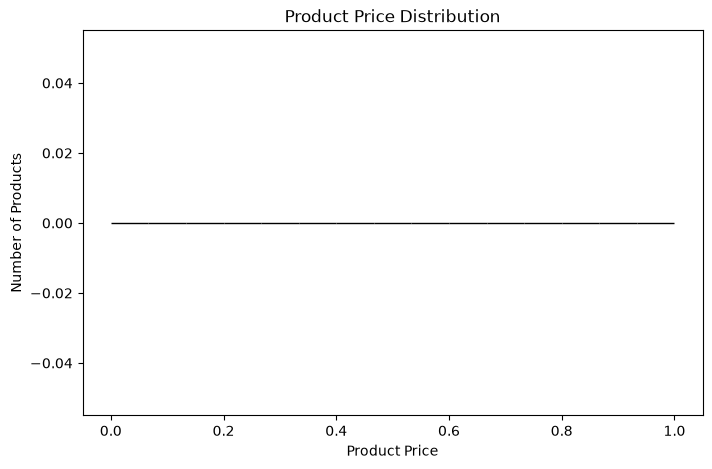

In [24]:
plt.figure(figsize=(8, 5))

plt.hist(df_all["Price"].dropna(), bins=15, edgecolor="black")

plt.title("Product Price Distribution")
plt.xlabel("Product Price")
plt.ylabel("Number of Products")

plt.show()

In [25]:
print("Price Data Type:")
print(df_all["Price"].dtype)

print("\nFirst 10 Price Values:")
print(df_all["Price"].head(10))

print("\nValid Price Count:")
print(df_all["Price"].notna().sum())

print("\nMissing Price Count:")
print(df_all["Price"].isna().sum())

Price Data Type:
float64

First 10 Price Values:
0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
5   NaN
6   NaN
7   NaN
8   NaN
9   NaN
Name: Price, dtype: float64

Valid Price Count:
0

Missing Price Count:
1000


In [26]:
print("First 5 Original Scraped Records:")

for product in all_products[:5]:
    print(product)

First 5 Original Scraped Records:
{'Product_Name': 'A Light in the Attic', 'Price': 'Â£51.77', 'Rating': 'Three'}
{'Product_Name': 'Tipping the Velvet', 'Price': 'Â£53.74', 'Rating': 'One'}
{'Product_Name': 'Soumission', 'Price': 'Â£50.10', 'Rating': 'One'}
{'Product_Name': 'Sharp Objects', 'Price': 'Â£47.82', 'Rating': 'Four'}
{'Product_Name': 'Sapiens: A Brief History of Humankind', 'Price': 'Â£54.23', 'Rating': 'Five'}


In [27]:
import pandas as pd

# Rebuild DataFrame from original scraped data
df_all = pd.DataFrame(all_products)

# Clean Price column
df_all["Price"] = (
    df_all["Price"]
    .astype(str)
    .str.extract(r'(\d+\.?\d*)')[0]
    .astype(float)
)

# Convert Rating words into numbers
rating_mapping = {
    "One": 1,
    "Two": 2,
    "Three": 3,
    "Four": 4,
    "Five": 5
}

df_all["Rating"] = df_all["Rating"].map(rating_mapping)

# Display corrected data
display(df_all.head())

print("\nMissing Values:")
print(df_all.isnull().sum())

print("\nData Types:")
print(df_all.dtypes)

,Product_Name,Price,Rating
0,A Light in the Attic,51.77,3
1,Tipping the Velvet,53.74,1
2,Soumission,50.10,1
3,Sharp Objects,47.82,4
4,Sapiens: A Brief History of Humankind,54.23,5



Missing Values:
Product_Name    0
Price           0
Rating          0
dtype: int64

Data Types:
Product_Name        str
Price           float64
Rating            int64
dtype: object


In [28]:
print("Dataset Shape:", df_all.shape)

print("\nValid Price Count:")
print(df_all["Price"].notna().sum())

print("\nMissing Price Count:")
print(df_all["Price"].isna().sum())

print("\nPrice Summary:")
print(df_all["Price"].describe())

print("\nRating Values:")
print(df_all["Rating"].value_counts().sort_index())

display(df_all.head())

Dataset Shape: (1000, 3)

Valid Price Count:
1000

Missing Price Count:
0

Price Summary:
count    1000.00000
mean       35.07035
std        14.44669
min        10.00000
25%        22.10750
50%        35.98000
75%        47.45750
max        59.99000
Name: Price, dtype: float64

Rating Values:
Rating
1    226
2    196
3    203
4    179
5    196
Name: count, dtype: int64


,Product_Name,Price,Rating
0,A Light in the Attic,51.77,3
1,Tipping the Velvet,53.74,1
2,Soumission,50.10,1
3,Sharp Objects,47.82,4
4,Sapiens: A Brief History of Humankind,54.23,5


In [29]:
# Create Rating Category
def rating_category(rating):
    if pd.isna(rating):
        return "Not Rated"
    elif rating >= 4.5:
        return "Excellent"
    elif rating >= 4:
        return "Good"
    elif rating >= 3:
        return "Average"
    else:
        return "Poor"

df_all["Rating_Category"] = df_all["Rating"].apply(rating_category)


# Create Price Category
def price_category(price):
    if pd.isna(price):
        return "Unknown"
    elif price < 20:
        return "Budget"
    elif price < 40:
        return "Mid-Range"
    else:
        return "Premium"

df_all["Price_Category"] = df_all["Price"].apply(price_category)

display(df_all.head())

,Product_Name,Price,Rating,Rating_Category,Price_Category
0,A Light in the Attic,51.77,3,Average,Premium
1,Tipping the Velvet,53.74,1,Poor,Premium
2,Soumission,50.10,1,Poor,Premium
3,Sharp Objects,47.82,4,Good,Premium
4,Sapiens: A Brief History of Humankind,54.23,5,Excellent,Premium


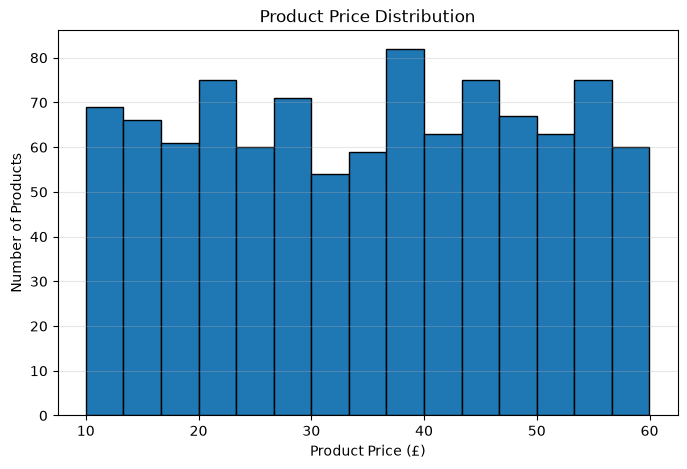

In [30]:
plt.figure(figsize=(8, 5))

plt.hist(
    df_all["Price"].dropna(),
    bins=15,
    edgecolor="black"
)

plt.title("Product Price Distribution")
plt.xlabel("Product Price (£)")
plt.ylabel("Number of Products")

plt.grid(axis="y", alpha=0.3)
plt.show()

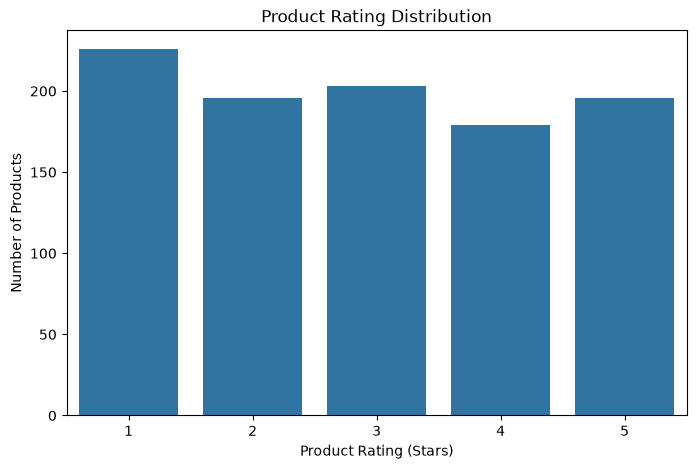

In [31]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_all,
    x="Rating",
    order=[1, 2, 3, 4, 5]
)

plt.title("Product Rating Distribution")
plt.xlabel("Product Rating (Stars)")
plt.ylabel("Number of Products")

plt.show()

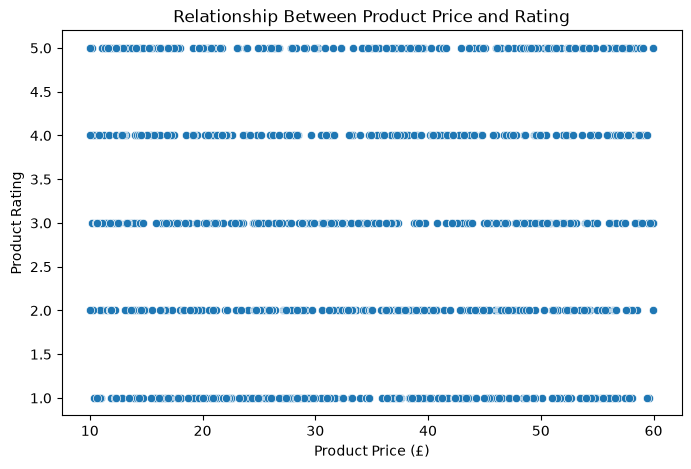

In [32]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_all,
    x="Price",
    y="Rating"
)

plt.title("Relationship Between Product Price and Rating")
plt.xlabel("Product Price (£)")
plt.ylabel("Product Rating")

plt.show()

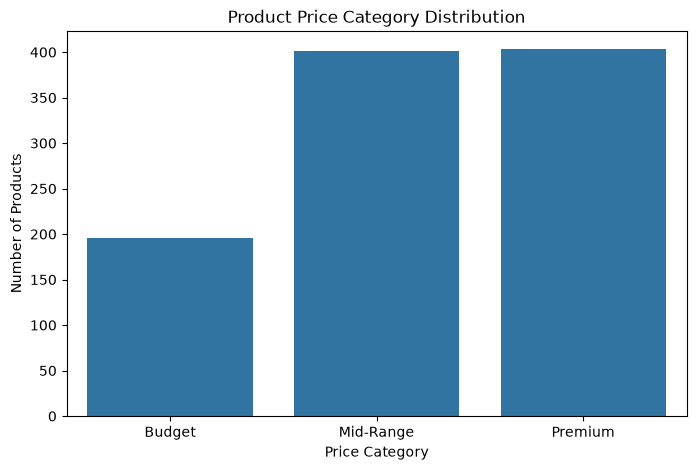

In [33]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_all,
    x="Price_Category",
    order=["Budget", "Mid-Range", "Premium"]
)

plt.title("Product Price Category Distribution")
plt.xlabel("Price Category")
plt.ylabel("Number of Products")

plt.show()


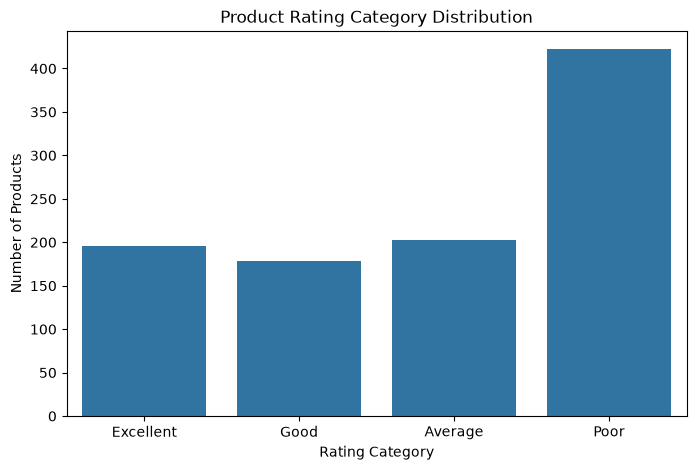

In [34]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_all,
    x="Rating_Category",
    order=["Excellent", "Good", "Average", "Poor"]
)

plt.title("Product Rating Category Distribution")
plt.xlabel("Rating Category")
plt.ylabel("Number of Products")

plt.show()

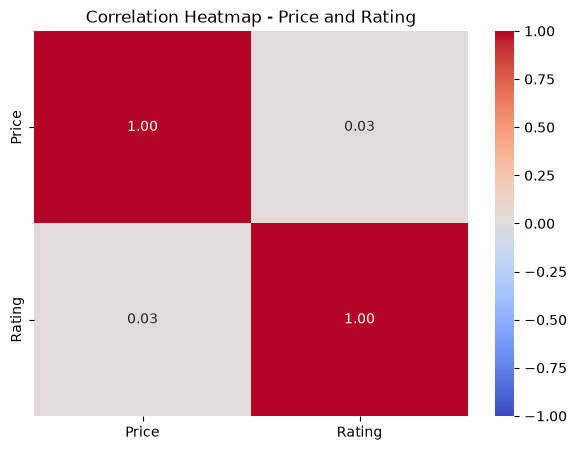

In [35]:
# Select numerical columns
numeric_df = df_all[["Price", "Rating"]]

# Calculate correlation
correlation = numeric_df.corr()

# Create heatmap
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap - Price and Rating")
plt.show()

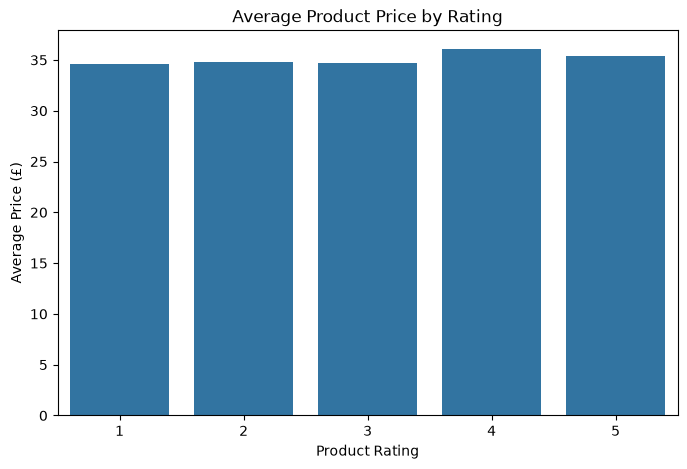

In [36]:
avg_price = df_all.groupby("Rating")["Price"].mean().reset_index()

plt.figure(figsize=(8, 5))

sns.barplot(
    data=avg_price,
    x="Rating",
    y="Price"
)

plt.title("Average Product Price by Rating")
plt.xlabel("Product Rating")
plt.ylabel("Average Price (£)")

plt.show()

In [37]:
print("MARKETSCOPE - EDA INSIGHTS")
print("---------------------------")

print("1. Total Products:", df_all["Product_Name"].nunique())

print("\n2. Average Price:", round(df_all["Price"].mean(), 2))

print("\n3. Highest Price:", df_all["Price"].max())

print("\n4. Lowest Price:", df_all["Price"].min())

print("\n5. Average Rating:", round(df_all["Rating"].mean(), 2))

print("\n6. Most Common Rating:")
print(df_all["Rating"].mode()[0])

print("\n7. Most Common Price Category:")
print(df_all["Price_Category"].mode()[0])

print("\n8. Most Common Rating Category:")
print(df_all["Rating_Category"].mode()[0])

MARKETSCOPE - EDA INSIGHTS
---------------------------
1. Total Products: 999

2. Average Price: 35.07

3. Highest Price: 59.99

4. Lowest Price: 10.0

5. Average Rating: 2.92

6. Most Common Rating:
1

7. Most Common Price Category:
Premium

8. Most Common Rating Category:
Poor


In [38]:
print("TOP 5 MOST EXPENSIVE PRODUCTS")
display(
    df_all.nlargest(5, "Price")[["Product_Name", "Price", "Rating"]]
)

print("\nTOP 5 LEAST EXPENSIVE PRODUCTS")
display(
    df_all.nsmallest(5, "Price")[["Product_Name", "Price", "Rating"]]
)

TOP 5 MOST EXPENSIVE PRODUCTS


,Product_Name,Price,Rating
648,The Perfect Play (Play by Play #1),59.99,3
617,Last One Home (New Beginnings #1),59.98,3
860,Civilization and Its Discontents,59.95,2
560,The Barefoot Contessa Cookbook,59.92,5
366,The Diary of a Young Girl,59.90,3



TOP 5 LEAST EXPENSIVE PRODUCTS


,Product_Name,Price,Rating
638,An Abundance of Katherines,10.00,5
501,The Origin of Species,10.01,4
716,The Tipping Point: How Little Things Can Make ...,10.02,2
84,Patience,10.16,3
302,Greek Mythic History,10.23,5


In [39]:
# Save cleaned dataset
df_all.to_csv("cleaned_products.csv", index=False)

print("Dataset saved successfully!")
print("File Name: cleaned_products.csv")

Dataset saved successfully!
File Name: cleaned_products.csv


In [40]:
quality_report = pd.DataFrame({
    "Column": df_all.columns,
    "Data_Type": df_all.dtypes.astype(str).values,
    "Missing_Values": df_all.isnull().sum().values,
    "Unique_Values": df_all.nunique().values
})

display(quality_report)

,Column,Data_Type,Missing_Values,Unique_Values
0,Product_Name,str,0,999
1,Price,float64,0,903
2,Rating,int64,0,5
3,Rating_Category,str,0,4
4,Price_Category,str,0,3


In [41]:
quality_report.to_csv("data_quality_report.csv", index=False)

print("Data Quality Report saved successfully!")

Data Quality Report saved successfully!


In [42]:
import scipy.stats as stats
import numpy as np

print("Statistical libraries imported successfully!")

Statistical libraries imported successfully!


In [43]:
pearson_corr, p_value = stats.pearsonr(
    df_all["Price"],
    df_all["Rating"]
)

print("Pearson Correlation:", round(pearson_corr, 4))
print("P-value:", round(p_value, 4))

Pearson Correlation: 0.0282
P-value: 0.3736


In [44]:
# Remove missing values before testing
clean_data = df_all[["Price", "Rating"]].dropna()

# Perform Spearman correlation
spearman_corr, p_value = stats.spearmanr(
    clean_data["Price"],
    clean_data["Rating"]
)

print("Spearman Correlation:", round(spearman_corr, 4))
print("P-value:", round(p_value, 4))

Spearman Correlation: 0.0292
P-value: 0.356


In [45]:
# Create two groups
low_rated = df_all[df_all["Rating"].isin([1, 2])]["Price"].dropna()

high_rated = df_all[df_all["Rating"].isin([4, 5])]["Price"].dropna()

# Perform independent t-test
t_stat, p_value = stats.ttest_ind(
    low_rated,
    high_rated,
    equal_var=False
)

print("Low-Rated Books Average Price:", round(low_rated.mean(), 2))
print("High-Rated Books Average Price:", round(high_rated.mean(), 2))

print("\nT-Statistic:", round(t_stat, 4))
print("P-value:", round(p_value, 4))

Low-Rated Books Average Price: 34.68
High-Rated Books Average Price: 35.72

T-Statistic: -1.0135
P-value: 0.3111


In [46]:
from scipy import stats
import numpy as np

# Remove missing prices
prices = df_all["Price"].dropna()

# Calculate mean and standard error
mean_price = prices.mean()
sem_price = stats.sem(prices)

# Calculate 95% confidence interval
confidence_interval = stats.t.interval(
    confidence=0.95,
    df=len(prices) - 1,
    loc=mean_price,
    scale=sem_price
)

print("Average Price:", round(mean_price, 2))
print("95% Confidence Interval:", confidence_interval)

Average Price: 35.07
95% Confidence Interval: (np.float64(34.17386521396868), np.float64(35.96683478603131))


In [47]:
# Calculate individual test results
pearson_result = stats.pearsonr(clean_data["Price"], clean_data["Rating"])
spearman_result = stats.spearmanr(clean_data["Price"], clean_data["Rating"])
ttest_result = stats.ttest_ind(low_rated, high_rated, equal_var=False)

hypothesis_results = pd.DataFrame({
    "Test": ["Pearson Correlation", "Spearman Correlation", "Independent T-Test"],
    "Test_Statistic": [
        pearson_result.statistic,
        spearman_result.statistic,
        ttest_result.statistic
    ],
    "P_Value": [
        pearson_result.pvalue,
        spearman_result.pvalue,
        ttest_result.pvalue
    ]
})

hypothesis_results["Decision"] = hypothesis_results["P_Value"].apply(
    lambda p: "Reject H0" if p < 0.05 else "Fail to reject H0"
)

display(hypothesis_results.round(4))

,Test,Test_Statistic,P_Value,Decision
0,Pearson Correlation,0.0282,0.3736,Fail to reject H0
1,Spearman Correlation,0.0292,0.3560,Fail to reject H0
2,Independent T-Test,-1.0135,0.3111,Fail to reject H0


In [48]:
import statsmodels.api as sm

print("Statsmodels imported successfully!")

Statsmodels imported successfully!


In [49]:
regression_data = df_all[["Price", "Rating"]].dropna()

X = regression_data[["Price"]]
y = regression_data["Rating"]

# Add constant
X = sm.add_constant(X)

print("Independent Variable: Price")
print("Dependent Variable: Rating")

display(regression_data.head())

Independent Variable: Price
Dependent Variable: Rating


,Price,Rating
0,51.77,3
1,53.74,1
2,50.10,1
3,47.82,4
4,54.23,5


In [50]:
# Build OLS regression model
model = sm.OLS(y, X).fit()

# Display model summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                 Rating   R-squared:                       0.001
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                    0.7924
Date:                Tue, 10 Nov 2026   Prob (F-statistic):              0.374
Time:                        15:21:03   Log-Likelihood:                -1779.2
No. Observations:                1000   AIC:                             3562.
Df Residuals:                     998   BIC:                             3572.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.8249      0.119     23.698      0.0

In [51]:
# Extract regression coefficients
print("REGRESSION COEFFICIENTS")
print(model.params)

print("\nP-VALUES")
print(model.pvalues)

print("\nCONFIDENCE INTERVALS")
print(model.conf_int())

print("\nR-SQUARED:", round(model.rsquared, 4))

print("ADJUSTED R-SQUARED:", round(model.rsquared_adj, 4))

print("F-STATISTIC:", round(model.fvalue, 4))

REGRESSION COEFFICIENTS
const    2.824883
Price    0.002798
dtype: float64

P-VALUES
const    7.469634e-99
Price    3.735963e-01
dtype: float64

CONFIDENCE INTERVALS
             0         1
const  2.59097  3.058797
Price -0.00337  0.008965

R-SQUARED: 0.0008
ADJUSTED R-SQUARED: -0.0002
F-STATISTIC: 0.7924


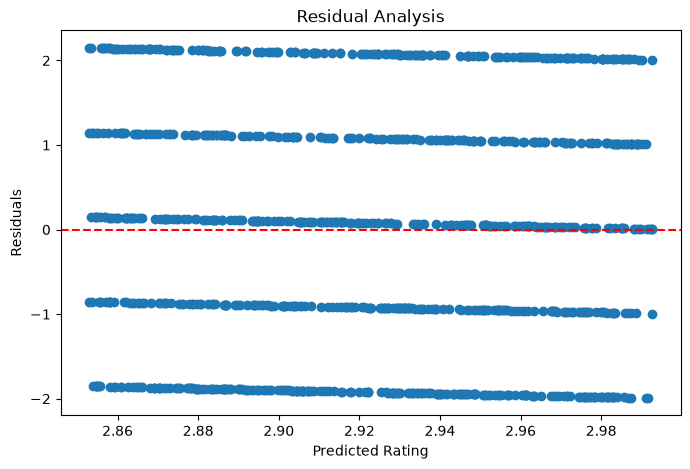

In [52]:
# Calculate predicted values
predictions = model.predict(X)

# Calculate residuals
residuals = y - predictions

# Residual plot
plt.figure(figsize=(8, 5))

plt.scatter(predictions, residuals)

plt.axhline(y=0, color="red", linestyle="--")

plt.title("Residual Analysis")
plt.xlabel("Predicted Rating")
plt.ylabel("Residuals")

plt.show()

In [53]:
# Shapiro-Wilk normality test
shapiro_stat, shapiro_p = stats.shapiro(residuals)

print("Shapiro-Wilk Test Statistic:", round(shapiro_stat, 4))
print("P-value:", round(shapiro_p, 4))

if shapiro_p > 0.05:
    print("Residuals are approximately normally distributed.")
else:
    print("Evidence suggests residuals are not normally distributed.")

Shapiro-Wilk Test Statistic: 0.8968
P-value: 0.0
Evidence suggests residuals are not normally distributed.


In [54]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Machine Learning libraries imported successfully!")

Machine Learning libraries imported successfully!


In [55]:
# Prepare features and target
ml_data = df_all[["Price", "Rating"]].dropna()

X = ml_data[["Price"]]
y = ml_data["Rating"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Training Data Shape: (800, 1)
Testing Data Shape: (200, 1)


In [56]:
# Create Linear Regression model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Make predictions
lr_predictions = lr_model.predict(X_test)

print("Linear Regression Model Trained Successfully!")

# Display first 10 predictions
print("\nActual Ratings:")
print(y_test.head(10).values)

print("\nPredicted Ratings:")
print(lr_predictions[:10])

Linear Regression Model Trained Successfully!

Actual Ratings:
[5 1 3 5 3 1 1 2 2 1]

Predicted Ratings:
[2.81117574 2.84517367 2.89141798 2.94293107 2.84364288 2.86596403
 2.8310405  2.84506687 2.89942796 2.85653005]


In [57]:
# Create Decision Tree model
dt_model = DecisionTreeRegressor(random_state=42)

# Train the model
dt_model.fit(X_train, y_train)

# Make predictions
dt_predictions = dt_model.predict(X_test)

print("Decision Tree Regressor Trained Successfully!")

print("\nActual Ratings:")
print(y_test.head(10).values)

print("\nPredicted Ratings:")
print(dt_predictions[:10])

Decision Tree Regressor Trained Successfully!

Actual Ratings:
[5 1 3 5 3 1 1 2 2 1]

Predicted Ratings:
[3. 4. 4. 2. 4. 4. 5. 3. 3. 4.]


In [58]:
# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_predictions = rf_model.predict(X_test)

print("Random Forest Regressor Trained Successfully!")

print("\nActual Ratings:")
print(y_test.head(10).values)

print("\nPredicted Ratings:")
print(rf_predictions[:10])

Random Forest Regressor Trained Successfully!

Actual Ratings:
[5 1 3 5 3 1 1 2 2 1]

Predicted Ratings:
[3.01 3.74 3.19 3.11 3.5  3.85 4.8  3.46 2.81 3.09]


In [59]:
# Function to evaluate models
def evaluate_model(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)

    return mae, mse, rmse, r2


# Evaluate all three models
lr_results = evaluate_model(y_test, lr_predictions)
dt_results = evaluate_model(y_test, dt_predictions)
rf_results = evaluate_model(y_test, rf_predictions)


# Create comparison table
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        lr_results[0],
        dt_results[0],
        rf_results[0]
    ],
    "MSE": [
        lr_results[1],
        dt_results[1],
        rf_results[1]
    ],
    "RMSE": [
        lr_results[2],
        dt_results[2],
        rf_results[2]
    ],
    "R2 Score": [
        lr_results[3],
        dt_results[3],
        rf_results[3]
    ]
})

display(model_comparison.round(4))

,Model,MAE,MSE,RMSE,R2 Score
0,Linear Regression,1.2325,2.0702,1.4388,-0.0103
1,Decision Tree,1.6675,4.1888,2.0466,-1.0442
2,Random Forest,1.5175,3.2714,1.8087,-0.5965


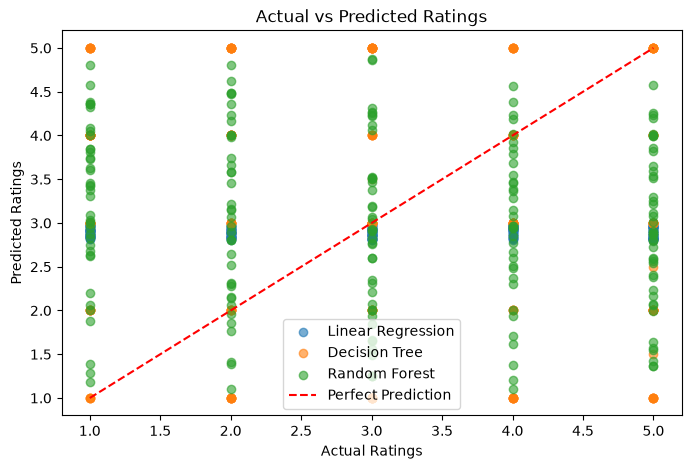

In [60]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, lr_predictions, label="Linear Regression", alpha=0.6)
plt.scatter(y_test, dt_predictions, label="Decision Tree", alpha=0.6)
plt.scatter(y_test, rf_predictions, label="Random Forest", alpha=0.6)

plt.plot(
    [1, 5],
    [1, 5],
    color="red",
    linestyle="--",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted Ratings")
plt.xlabel("Actual Ratings")
plt.ylabel("Predicted Ratings")
plt.legend()

plt.show()

In [61]:
best_model = model_comparison.loc[
    model_comparison["RMSE"].idxmin()
]

print("BEST PERFORMING MODEL")
print("----------------------")

print("Model:", best_model["Model"])
print("MAE:", round(best_model["MAE"], 4))
print("MSE:", round(best_model["MSE"], 4))
print("RMSE:", round(best_model["RMSE"], 4))
print("R2 Score:", round(best_model["R2 Score"], 4))

BEST PERFORMING MODEL
----------------------
Model: Linear Regression
MAE: 1.2325
MSE: 2.0702
RMSE: 1.4388
R2 Score: -0.0103


In [62]:
model_comparison.to_csv("model_comparison.csv", index=False)

print("Model comparison results saved successfully!")

Model comparison results saved successfully!


In [63]:
import joblib

joblib.dump(rf_model, "best_model.pkl")

print("Best model saved successfully!")

Best model saved successfully!


In [64]:
import joblib

best_model_name = best_model["Model"]

if best_model_name == "Linear Regression":
    final_model = lr_model

elif best_model_name == "Decision Tree":
    final_model = dt_model

else:
    final_model = rf_model

joblib.dump(final_model, "best_model.pkl")

print("Best Model:", best_model_name)
print("Model saved successfully!")

Best Model: Linear Regression
Model saved successfully!


In [65]:
loaded_model = joblib.load("best_model.pkl")

new_product = pd.DataFrame({
    "Price": [25.00]
})

predicted_rating = loaded_model.predict(new_product)

print("New Product Price: £25.00")
print("Predicted Rating:", round(predicted_rating[0], 2))

New Product Price: £25.00
Predicted Rating: 2.86


### Machine Learning Conclusion

In this project, three machine learning regression algorithms were implemented:

1. Linear Regression
2. Decision Tree Regressor
3. Random Forest Regressor

The models were evaluated using MAE, MSE, RMSE, and R² score. Their performance was compared to identify the best-performing model.

The selected model was saved as `best_model.pkl` using Joblib and tested with a new product price to generate a predicted rating.

**Limitation:** This is a practice experiment using book-product data. Price alone is not sufficient to reliably predict product ratings, and further testing with a suitable e-commerce dataset is required.

In [66]:
import os

print("SAVED PROJECT FILES")
print("-------------------")

for file in os.listdir():
    if file.endswith((".csv", ".pkl")):
        print(file)

SAVED PROJECT FILES
-------------------
best_model.pkl
cleaned_products.csv
data_quality_report.csv
model_comparison.csv


In [67]:
df_all.to_excel("MarketScope_Final_Dataset.xlsx", index=False)

print("Excel dataset created successfully!")

Excel dataset created successfully!


In [69]:
import os

file_name = "MarketScope_Final_Dataset.xlsx"

if os.path.exists(file_name):
    print("File exists:", file_name)
    print("File size:", round(os.path.getsize(file_name) / 1024, 2), "KB")
else:
    print("File not found!")

File exists: MarketScope_Final_Dataset.xlsx
File size: 51.47 KB


In [70]:
import pandas as pd
df = pd.read_csv("cleaned_products.csv")
df.insert(0, "Product_ID", range(1, len(df) + 1))
df.to_csv("cleaned_products_with_id.csv", index=False)